# Landau Tail Fraction — confronto sensori
Plot dell'**LTF** = N(area > 1.5·MPV) / N(area > MPV) in funzione di **bias voltage** e **carica raccolta**, per produzione e fluenza.

- **Sezione 1**: dati (voltage, charge, ltf per sensore)
- **Sezione 2**: funzioni di plotting
- **Sezione 3**: plot per produzione

I valori `ltf` sono da incollare dall'output di `beta_analyzer.ipynb` (cella LTF), insieme a `voltage` e `charge`.


In [174]:

import numpy as np
import matplotlib.pyplot as plt
import mplhep as hep

%matplotlib widget

plt.style.use(hep.style.CMS)


In [175]:

# Titolo e sottotitolo di default
PLOT_TITLE    = "Landau Tail Fraction"
PLOT_SUBTITLE = "Beta setup"
# ── Palette colori — scegli da qui per i nuovi sensori ──────
PALETTE = {
    # reds
    'red':              '#bd1f01',
    'red_light':        '#e05040',
    'red_dark':         '#7a1200',
    'crimson':          '#dc143c',
    'rose':             '#e8627a',

    # oranges
    'orange':           '#e07b00',
    'orange_light':     '#f5a233',
    'orange_dark':      '#a05500',
    'dark_orange':      '#e76300',
    'amber':            '#ffb300',

    # yellows
    'yellow':           '#ffa90e',
    'yellow_light':     '#ffd54f',
    'yellow_dark':      '#c77800',
    'gold':             '#d4a017',
    'lime_yellow':      '#d4e157',

    # greens
    'green':            '#417328',
    'green_light':      '#66a63e',
    'green_dark':       '#264d14',
    'lime':             '#8bc34a',
    'mint':             '#4caf7d',
    'forest':           '#2e7d32',

    # teals / cyans
    'teal':             '#00897b',
    'teal_light':       '#4db6ac',
    'teal_dark':        '#00574b',
    'cyan':             '#92dadd',
    'cyan_dark':        '#0097a7',
    'aqua':             '#00bcd4',

    # blues
    'blue':             '#3f90da',
    'blue_light':       '#7ec8f0',
    'blue_dark':        '#1565c0',
    'dark_blue':        '#1a3f5c',
    'navy':             '#0d2340',
    'sky':              '#64b5f6',
    'cobalt':           '#1e4d8c',
    'indigo':           '#3949ab',

    # purples
    'purple':           '#832db6',
    'purple_light':     '#b36fd4',
    'purple_dark':      '#560a85',
    'violet':           '#6a1b9a',
    'lavender':         '#ce93d8',
    'mauve':            '#c77dff',

    # pinks
    'pink':             '#e35be5',
    'pink_light':       '#f48fb1',
    'pink_dark':        '#ad1457',
    'hot_pink':         '#f06292',
    'fuchsia':          '#e91e8c',

    # browns
    'brown':            '#a96b59',
    'brown_light':      '#c8957c',
    'brown_dark':       '#6d3b2b',
    'tan':              '#c4a882',
    'sienna':           '#a0522d',

    # olives / neutrals
    'olive':            '#b9ac70',
    'olive_dark':       '#827717',
    'khaki':            '#d4c97a',
    'sand':             '#c2b280',

    # greys
    'grey':             '#717581',
    'grey_light':       '#aab0ba',
    'grey_dark':        '#424651',
    'charcoal':         '#2e3035',
    'silver':           '#c0c4cc',
}

RED          = PALETTE['red']
RED_LIGHT    = PALETTE['red_light']
RED_DARK     = PALETTE['red_dark']
CRIMSON      = PALETTE['crimson']
ROSE         = PALETTE['rose']

ORANGE       = PALETTE['orange']
ORANGE_LIGHT = PALETTE['orange_light']
ORANGE_DARK  = PALETTE['orange_dark']
DARK_ORANGE  = PALETTE['dark_orange']
AMBER        = PALETTE['amber']

YELLOW       = PALETTE['yellow']
YELLOW_LIGHT = PALETTE['yellow_light']
YELLOW_DARK  = PALETTE['yellow_dark']
GOLD         = PALETTE['gold']
LIME_YELLOW  = PALETTE['lime_yellow']

GREEN        = PALETTE['green']
GREEN_LIGHT  = PALETTE['green_light']
GREEN_DARK   = PALETTE['green_dark']
LIME         = PALETTE['lime']
MINT         = PALETTE['mint']
FOREST       = PALETTE['forest']

TEAL         = PALETTE['teal']
TEAL_LIGHT   = PALETTE['teal_light']
TEAL_DARK    = PALETTE['teal_dark']
CYAN         = PALETTE['cyan']
CYAN_DARK    = PALETTE['cyan_dark']
AQUA         = PALETTE['aqua']

BLUE         = PALETTE['blue']
BLUE_LIGHT   = PALETTE['blue_light']
BLUE_DARK    = PALETTE['blue_dark']
DARK_BLUE    = PALETTE['dark_blue']
NAVY         = PALETTE['navy']
SKY          = PALETTE['sky']
COBALT       = PALETTE['cobalt']
INDIGO       = PALETTE['indigo']

PURPLE       = PALETTE['purple']
PURPLE_LIGHT = PALETTE['purple_light']
PURPLE_DARK  = PALETTE['purple_dark']
VIOLET       = PALETTE['violet']
LAVENDER     = PALETTE['lavender']
MAUVE        = PALETTE['mauve']

PINK         = PALETTE['pink']
PINK_LIGHT   = PALETTE['pink_light']
PINK_DARK    = PALETTE['pink_dark']
HOT_PINK     = PALETTE['hot_pink']
FUCHSIA      = PALETTE['fuchsia']

BROWN        = PALETTE['brown']
BROWN_LIGHT  = PALETTE['brown_light']
BROWN_DARK   = PALETTE['brown_dark']
TAN          = PALETTE['tan']
SIENNA       = PALETTE['sienna']

OLIVE        = PALETTE['olive']
OLIVE_DARK   = PALETTE['olive_dark']
KHAKI        = PALETTE['khaki']
SAND         = PALETTE['sand']

GREY         = PALETTE['grey']
GREY_LIGHT   = PALETTE['grey_light']
GREY_DARK    = PALETTE['grey_dark']
CHARCOAL     = PALETTE['charcoal']
SILVER       = PALETTE['silver']

## 1. Inserisci i dati
Ogni sensore è un dizionario con:
- `label`, `color`, `marker`, `linestyle`, `hollow` (opzionale)
- `voltage`: bias [V]
- `charge`: carica raccolta [fC]
- `ltf`: Landau Tail Fraction (`None` = punto mancante, viene saltato nel plot)
- `ltf_err` (opzionale): incertezze sull'LTF

Esclusi rispetto a `beta_2026_plotter`: le misure TB e la vecchia produzione HPK2.


## 2. Funzioni di plotting

In [176]:
import os

SAVE_IMAGES = False         # True -> salva i plot (vedi cella di configurazione)
SAVE_DIR    = 'LTF_images'  # cartella di output


def _prepare_xy(sensor, xkey):
    """(x, ltf, ltf_err) senza i punti con valori mancanti (None)."""
    xs, ys = sensor[xkey], sensor['ltf']
    errs   = sensor.get('ltf_err')
    x_out, y_out, e_out = [], [], []
    for i, (xx, yy) in enumerate(zip(xs, ys)):
        if xx is None or yy is None:
            continue
        x_out.append(xx); y_out.append(yy)
        e_out.append(errs[i] if errs is not None else None)
    e_out = None if all(e is None for e in e_out) else np.array(e_out, dtype=float)
    return np.array(x_out), np.array(y_out), e_out


def _resolve(selection):
    if selection == 'all':
        return sensors
    if isinstance(selection, int):
        return [sensors[selection]]
    return [sensors[i] for i in selection]


def _errorbar_kwargs(sensor, e):
    mfc = 'none' if sensor.get('hollow', False) else sensor['color']
    return dict(
        label           = sensor['label'],
        color           = sensor['color'],
        linestyle       = sensor['linestyle'],
        marker          = sensor.get('marker', 'o'),
        markersize      = sensor.get('markersize', 5),
        linewidth       = 1.6,
        capsize         = 3 if e is not None else 0,
        markerfacecolor = mfc,
        markeredgewidth = 1.5,
    )


def plot_ltf(sensor_list, xkey, title=PLOT_TITLE, subtitle=PLOT_SUBTITLE,
             ylim=None, xlim=None, xlog=False, save_path=None, figsize=(9, 7)):
    """LTF vs `xkey` ('voltage' oppure 'charge'). xlog=True -> asse x logaritmico."""
    xlabel = {'voltage': 'Bias voltage [V]', 'charge': 'Collected charge [fC]'}[xkey]
    fig, ax = plt.subplots(figsize=figsize)
    for s in sensor_list:
        x, y, e = _prepare_xy(s, xkey)
        if len(x) == 0:
            continue
        o = np.argsort(x)
        ax.errorbar(x[o], y[o], yerr=None if e is None else e[o], **_errorbar_kwargs(s, e))

    ax.set_xlabel(xlabel)
    ax.set_ylabel('LTF (N>1.5·MPV / N>MPV)')
    if ylim: ax.set_ylim(*ylim)
    if xlim: ax.set_xlim(*xlim)
    if xlog: ax.set_xscale('log')
    leg = ax.legend(loc='best', frameon=True, fontsize=11)
    leg.set_draggable(True)
    ax.text(0.03, 0.97, subtitle, transform=ax.transAxes,
            va='top', ha='left', fontsize=12)
    hep.cms.label(label='ETL Preliminary', data=True, rlabel=title, ax=ax, fontsize=15)
    plt.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=200, bbox_inches='tight')
        print(f'Salvato: {save_path}')
    plt.show()
    return fig


def plot_two(selection, title, subtitle=PLOT_SUBTITLE,
             ylim=None, xlim_v=None, xlim_q=None, xlog_q=False,
             name=None, figsize=(9, 7)):
    """LTF vs bias e LTF vs carica per la selezione.
    Se SAVE_IMAGES=True e `name` è dato salva in SAVE_DIR:
    <name>_lft_vs_bias.png, <name>_lft_vs_charge.png"""
    sel   = _resolve(selection)
    save  = SAVE_IMAGES and name
    if save:
        os.makedirs(SAVE_DIR, exist_ok=True)
    sp    = lambda suffix: f'{SAVE_DIR}/{name}_lft_{suffix}.png' if save else None
    plot_ltf(sel, 'voltage', title=title, subtitle=subtitle, ylim=ylim, xlim=xlim_v,
             save_path=sp('vs_bias'),   figsize=figsize)
    plot_ltf(sel, 'charge',  title=title, subtitle=subtitle, ylim=ylim, xlim=xlim_q, xlog=xlog_q,
             save_path=sp('vs_charge'), figsize=figsize)


In [177]:
# ── schema ────────────────────────────────────────────────────────────────
# produzione → colore:  HPK B1=RED  HPK B2=ORANGE  HPK6=BLUE  FBK B1=GREEN
# fluenza    → shade:   non-irr=LIGHT  1e15=base  1.5e15=DARK
# sensore    → marker:  primo='o'  secondo='s'
# dati       → voltage [V] | charge [fC] | ltf (da incollare dall'output di beta_analyzer)
# ─────────────────────────────────────────────────────────────────────────

sensors = [

    ### ── HPK PRE-Series Batch 1 ── RED ─────────────────────────────────────
    # non irraggiato → RED_LIGHT
    {
        'label':      'HPK W5 S1 (Batch 1) - Beta',                           #1
        'color':      RED_LIGHT, 'marker': 'o', 'linestyle': '-',
        'voltage':    [130, 140, 150, 160, 170, 180, 190, 200],
        'charge':     [9.52, 11.04, 12.81, 15.09, 17.71, 21.82, 28.27, 38.99],
        'ltf':        [0.3040, 0.2638, 0.2410, 0.2183, 0.2110, 0.1963, 0.1418, 0.1173],
    },
    {
        'label':      'HPK W5 S2 (Batch 1) - Beta',                           #2
        'color':      RED_LIGHT, 'marker': 's', 'linestyle': '-',
        'voltage':    [120, 130, 140, 150, 160, 170, 180, 190, 200, 210],
        'charge':     [9.16, 10.37, 11.97, 13.55, 16.03, 19.12, 23.23, 28.71, 37.73, 57.01],
        'ltf':        [0.3002, 0.3126, 0.2916, 0.2913, 0.2672, 0.2119, 0.2039, 0.1806, 0.1473, 0.1249],

    },
    # 1e15 → RED
    {
        'label':      'HPK W1 S5 (Batch 1) 1e15 - Beta',                      #3
        'color':      RED, 'marker': 'o', 'linestyle': '-',
        'voltage':    [300, 350, 400, 500, 525, 550, 575, 600, 605],
        'charge':     [1.43, 1.64, 2.01, 3.38, 4.04, 4.83, 5.89, 7.63, 8.07],
        'ltf':        [0.3864, 0.4221, 0.4114, 0.3741, 0.3581, 0.3828, 0.3788, 0.3537, 0.3553],
    },
    {
        'label':      'HPK W6 S4 (Batch 1) 1e15 - Beta',                      #4
        'color':      RED, 'marker': 's', 'linestyle': '-',
        'voltage':    [300, 350, 400, 450, 500, 525, 550, 575, 600],
        'charge':     [1.62, 1.90, 2.47, 3.08, 4.32, 5.28, 6.65, 8.57, 11.13],
        'ltf':        [0.3616, 0.3869, 0.3543, 0.3854, 0.3781, 0.3591, 0.3611, 0.3030, 0.3092],
    },
    # 1.5e15 → RED_DARK
    {
        'label':      'HPK W1 S3 (Batch 1) 1.5e15 - Beta',                    #5
        'color':      RED_DARK, 'marker': 'o', 'linestyle': '-',
        'voltage':    [300, 350, 400, 450, 500, 525, 550, 575, 600],
        'charge':     [1.34, 1.38, 1.44, 1.59, 1.85, 2.07, 2.41, 2.72, 3.27],
        'ltf':        [0.3633, 0.3570, 0.4033, 0.3787, 0.4095, 0.4102, 0.3746, 0.3708, 0.3569],
    },
    {
        'label':      'HPK W1 S2 (Batch 1) 1.5e15 - Beta',                    #6
        'color':      RED_DARK, 'marker': 's', 'linestyle': '-',
        'voltage':    [300, 350, 400, 450, 500, 525, 550, 575, 600],
        'charge':     [1.03, 1.12, 1.24, 1.41, 1.65, 1.85, 2.07, 2.41, 2.71],
        'ltf':        [0.4055, 0.3803, 0.3603, 0.3727, 0.3736, 0.3643, 0.3770, 0.3692, 0.3829],
    },

    ### ── HPK PRE-Series Batch 2 ── ORANGE ───────────────────────────────────
    # non irraggiato → ORANGE_LIGHT
    {
        'label':      'HPK W81 S1 (Batch 2) - Beta',                          #7
        'color':      ORANGE_LIGHT, 'marker': 'o', 'linestyle': '-',
        'voltage':    [120, 130, 140, 150, 160, 170, 180, 190, 200],
        'charge':     [8.60, 9.99, 11.60, 13.13, 15.90, 19.23, 24.03, 30.63, 46.85],
        'ltf':        [0.3343, 0.2997, 0.2565, 0.2711, 0.2360, 0.2142, 0.1795, 0.1741, 0.1363],
    },
    {
        'label':      'HPK W81 S2 (Batch 2) - Beta',                          #8
        'color':      ORANGE_LIGHT, 'marker': 's', 'linestyle': '-',
        'voltage':    [120, 130, 140, 150, 160, 170, 180, 190, 200],
        'charge':     [10.10, 10.56, 12.78, 15.04, 16.43, 20.92, 24.43, 35.37, 44.45],
        'ltf':        [0.2952, 0.2525, 0.2308, 0.2469, 0.2842, 0.1461, 0.2200, 0.1029, 0.0659],
    },
    # 1e15 → ORANGE
    {
        'label':      'HPK W83 S4 (Batch 2) 1e15 - Beta',                     #9
        'color':      ORANGE, 'marker': 'o', 'linestyle': '-',
        'voltage':    [300, 350, 400, 450, 500, 525, 550, 575, 600, 605],
        'charge':     [1.59, 1.95, 2.48, 3.26, 4.52, 5.52, 6.94, 9.15, 11.99, 12.54],
        'ltf':        [0.4004, 0.3797, 0.3775, 0.3689, 0.3666, 0.3621, 0.3519, 0.3213, 0.3090, 0.2734],
    },
    {
        'label':      'HPK W82 S5 (Batch 2) 1e15 - Beta',                     #10
        'color':      ORANGE, 'marker': 's', 'linestyle': '-',
        'voltage':    [300, 350, 400, 450, 500, 525, 550, 575, 600],
        'charge':     [1.36, 1.52, 1.79, 2.21, 2.84, 3.45, 4.05, 6.15, 6.48],
        'ltf':        [0.3586, 0.3646, 0.3880, 0.3870, 0.3835, 0.3591, 0.3583, 0.3433, 0.3418],
    },
    # 1.5e15 → ORANGE_DARK
    {
        'label':      'HPK W82 S2 (Batch 2) 1.5e15 - Beta',                   #11
        'color':      ORANGE_DARK, 'marker': 'o', 'linestyle': '-',
        'voltage':    [300, 350, 400, 450, 500, 550, 575, 600, 605],
        'charge':     [1.24, 1.26, 1.43, 1.63, 1.97, 2.47, 2.92, 3.37, 3.45],
        'ltf':        [0.3768, 0.4165, 0.3953, 0.4131, 0.3926, 0.3853, 0.3732, 0.3518, 0.3664],
    },
    {
        'label':      'HPK W82 S3 (Batch 2) 1.5e15 - Beta',                   #12
        'color':      ORANGE_DARK, 'marker': 's', 'linestyle': '-',
        'voltage':    [300, 350, 400, 450, 500, 525, 550, 575, 600, 605],
        'charge':     [1.21, 1.24, 1.34, 1.51, 1.82, 2.02, 2.35, 2.65, 3.00, 3.21],
        'ltf':        [0.3717, 0.4025, 0.3846, 0.3971, 0.4386, 0.3920, 0.3783, 0.3630, 0.3723, 0.3696],
    },

    ### ── HPK6 ── BLUE ────────────────────────────────────────────────────────
    # non irraggiato → BLUE_LIGHT
    {
        'label':      'HPK6 S4-A - Beta',                                      #13
        'color':      BLUE_LIGHT, 'marker': 'o', 'linestyle': '-',
        'voltage':    [100, 110, 120, 130, 140, 150, 160, 170, 180, 190],
        'charge':     [7.26, 8.14, 9.29, 10.80, 12.60, 15.13, 18.52, 22.76, 28.42, 34.32],
        'ltf':        [0.3629, 0.3450, 0.3398, 0.3195, 0.3214, 0.2899, 0.2583, 0.2323, 0.2040, 0.1843],
    },
    {
        'label':      'HPK6 S2-B - Beta',                                      #14
        'color':      BLUE_LIGHT, 'marker': 's', 'linestyle': '-',
        'voltage':    [100, 110, 120, 130, 140, 150, 160, 170, 180, 190],
        'charge':     [7.72, 8.65, 10.03, 11.57, 13.80, 16.11, 19.70, 24.32, 30.80, 41.00],
        'ltf':        [0.3575, 0.3521, 0.3245, 0.3234, 0.2972, 0.2935, 0.2517, 0.2213, 0.1917, 0.1656],
    },
    # 1e15 → BLUE
    {
        'label':      'HPK6 S4-B 1e15 - Beta',                                #15
        'color':      BLUE, 'marker': 'o', 'linestyle': '-',
        'voltage':    [300, 350, 400, 450, 500, 525, 550, 575, 600],
        'charge':     [1.55, 1.96, 2.55, 3.47, 5.04, 6.39, 8.05, 10.62, 13.77],
        'ltf':        [0.4235, 0.4063, 0.4007, 0.3972, 0.3905, 0.3713, 0.3675, 0.3357, 0.3215],
    },
    {
        'label':      'HPK6 S5-A 1e15 - Beta',                                #16
        'color':      BLUE, 'marker': 's', 'linestyle': '-',
        'voltage':    [300, 350, 400, 450, 500, 525, 550, 575, 600],
        'charge':     [1.65, 2.06, 2.76, 3.91, 6.10, 7.93, 10.89, 14.92, 20.55],
        'ltf':        [0.3857, 0.3833, 0.3714, 0.3683, 0.3544, 0.3465, 0.2982, 0.2646, 0.2222],
    },
    # 1.5e15 → BLUE_DARK
    {
        'label':      'HPK6 S5-B 1.5e15 - Beta',                              #17
        'color':      BLUE_DARK, 'marker': 'o', 'linestyle': '-',
        'voltage':    [300, 350, 400, 450, 500, 525, 550, 575, 600],
        'charge':     [1.12, 1.14, 1.19, 1.27, 1.39, 1.48, 1.67, 1.88, 2.23],
        'ltf':        [0.4028, 0.3944, 0.4129, 0.4019, 0.4058, 0.3807, 0.3974, 0.4040, 0.3817],
    },
    {
        'label':      'HPK6 S2A 1.5e15 - Beta',                               #18
        'color':      BLUE_DARK, 'marker': 's', 'linestyle': '-',
        'voltage':    [300, 350, 400, 450, 500, 525, 550, 575, 600],
        'charge':     [1.03, 1.12, 1.24, 1.41, 1.65, 1.85, 2.07, 2.41, 2.71],
        'ltf':        [0.4055, 0.3803, 0.3703, 0.3727, 0.3736, 0.3843, 0.3770, 0.3692, 0.3829]
    },

    ### ── FBK PRE-Serie Batch 1 ── GREEN ─────────────────────────────────────
    # non irraggiato → GREEN_LIGHT
    {
        'label':      'FBK W16 S13 (Batch 1) - Beta',                         #19
        'color':      GREEN_LIGHT, 'marker': 'o', 'linestyle': '-',
        'voltage':    [120, 130, 140, 150, 160, 170, 180, 190, 200, 210, 220],
        'charge':     [7.05, 7.67, 8.03, 9.10, 11.33, 13.48, 15.70, 19.55, 28.20, 32.64, 37.06],
        'ltf':        [0.3255, 0.2879, 0.3240, 0.2803, 0.2303, 0.2184, 0.2014, 0.1947, 0.2074, 0.1560, 0.1378],
    },
    {
        'label':      'FBK W16 S52 (Batch 1) - Beta',                         #20
        'color':      GREEN_LIGHT, 'marker': 's', 'linestyle': '-',
        'voltage':    [120, 130, 140, 150, 160, 170, 180, 190, 200, 210, 220],
        'charge':     [8.24, 9.52, 9.98, 11.72, 13.27, 15.53, 17.82, 21.24, 25.82, 31.25, 37.30],
        'ltf':        [0.2886, 0.2817, 0.3086, 0.2834, 0.2795, 0.2365, 0.2268, 0.2106, 0.2002, 0.1860, 0.1626]
    },
    # 1e15 → GREEN
    {
        'label':      'FBK W18 S2 (Batch 1) 1e15 - Beta',                     #21
        'color':      GREEN, 'marker': 'o', 'linestyle': '-', 'hollow': True,
        'voltage':    [300, 350, 400, 450, 500, 525, 550, 575, 600],
        'charge':     [2.87, 4.30, 5.95, 8.72, 13.62, 16.18, 20.56, 25.12, 30.93],
        'ltf':        [0.4386, 0.3518, 0.3517, 0.3106, 0.2757, 0.2923, 0.2288, 0.1988, 0.1497],
    },
    {
        'label':      'FBK W16 S25 (Batch 1) 1e15 - Beta',                    #22
        'color':      GREEN, 'marker': 's', 'linestyle': '-', 'hollow': True,
        'voltage':    [300, 350, 400, 450, 500, 525, 550, 575, 600],
        'charge':     [2.68, 3.62, 5.27, 7.91, 13.14, 16.55, 20.42, 25.36, 29.86],
        'ltf':        [0.3668, 0.3666, 0.3350, 0.3272, 0.2560, 0.2275, 0.2241, 0.1554, 0.1381],
        
    },
    # 1.5e15 → GREEN_DARK
    {
        'label':      'FBK W16 S18 (Batch 1) 1.5e15 - Beta',                  #23
        'color':      GREEN_DARK, 'marker': 'o', 'linestyle': '-', 'hollow': True,
        'voltage':    [300, 350, 400, 450, 500, 525, 550, 575, 600],
        'charge':     [2.08, 2.57, 3.20, 4.08, 5.25, 6.16, 7.12, 8.54, 10.16],
        'ltf':        [0.4189, 0.4091, 0.4022, 0.4070, 0.4049, 0.4060, 0.3958, 0.3510, 0.3397],
    },
    {
        'label':      'FBK W16 S25 (Batch 1) 1.5e15 - Beta',                  #24
        'color':      GREEN_DARK, 'marker': 's', 'linestyle': '-', 'hollow': True,
        'voltage':    [300, 350, 400, 450, 500, 525, 550, 575, 600],
        'charge':     [1.53, 1.66, 1.91, 2.36, 3.13, 3.90, 4.61, 7.56, 9.47],
        'ltf':        [0.3808, 0.3826, 0.4015, 0.3783, 0.3640, 0.3594, 0.3260, 0.3474, 0.3185],
    },
]

In [178]:
# ── Schema colori ────────────────────────────────────────────
# True  → colore per FLUENZA (uguale in tutte le produzioni):
#         non irraggiato = rosso | 1e15 = blu | 1.5e15 = verde
# False → colore per PRODUZIONE (sfumatura = fluenza), come in sensors
COLOR_BY_FLUENCE = True

FLUENCE_COLORS = {
    'new':    RED,
    '1e15':   BLUE,
    '1.5e15': GREEN,
}

def _fluence(label):
    if '1.5e15' in label: return '1.5e15'
    if '1e15'   in label: return '1e15'
    return 'new'

for _s in sensors:
    _s.setdefault('color_prod', _s['color'])          # salva il colore originale
    _s['color'] = (FLUENCE_COLORS[_fluence(_s['label'])] if COLOR_BY_FLUENCE
                   else _s['color_prod'])


In [179]:
# ── Indici dei sensori ───────────────────────────────────────
for i, s in enumerate(sensors):
    print(f"[{i:2d}] {s['label']}")


[ 0] HPK W5 S1 (Batch 1) - Beta
[ 1] HPK W5 S2 (Batch 1) - Beta
[ 2] HPK W1 S5 (Batch 1) 1e15 - Beta
[ 3] HPK W6 S4 (Batch 1) 1e15 - Beta
[ 4] HPK W1 S3 (Batch 1) 1.5e15 - Beta
[ 5] HPK W1 S2 (Batch 1) 1.5e15 - Beta
[ 6] HPK W81 S1 (Batch 2) - Beta
[ 7] HPK W81 S2 (Batch 2) - Beta
[ 8] HPK W83 S4 (Batch 2) 1e15 - Beta
[ 9] HPK W82 S5 (Batch 2) 1e15 - Beta
[10] HPK W82 S2 (Batch 2) 1.5e15 - Beta
[11] HPK W82 S3 (Batch 2) 1.5e15 - Beta
[12] HPK6 S4-A - Beta
[13] HPK6 S2-B - Beta
[14] HPK6 S4-B 1e15 - Beta
[15] HPK6 S5-A 1e15 - Beta
[16] HPK6 S5-B 1.5e15 - Beta
[17] HPK6 S2A 1.5e15 - Beta
[18] FBK W16 S13 (Batch 1) - Beta
[19] FBK W16 S52 (Batch 1) - Beta
[20] FBK W18 S2 (Batch 1) 1e15 - Beta
[21] FBK W16 S25 (Batch 1) 1e15 - Beta
[22] FBK W16 S18 (Batch 1) 1.5e15 - Beta
[23] FBK W16 S25 (Batch 1) 1.5e15 - Beta


## 3. Genera i plot

Per ogni selezione: **LTF vs bias** e **LTF vs carica**. Il colore indica la produzione, la sfumatura la fluenza (chiaro = non irraggiato, scuro = 1.5e15).


In [180]:
# ── Salvataggio immagini ─────────────────────────────────────
SAVE_IMAGES = True       # True -> salva tutti i plot generati in SAVE_DIR
SAVE_DIR    = 'LTF_images' # file: <produzione>_lft_vs_bias.png / <produzione>_lft_vs_charge.png


Salvato: LTF_images/hpk_b1_lft_vs_bias.png


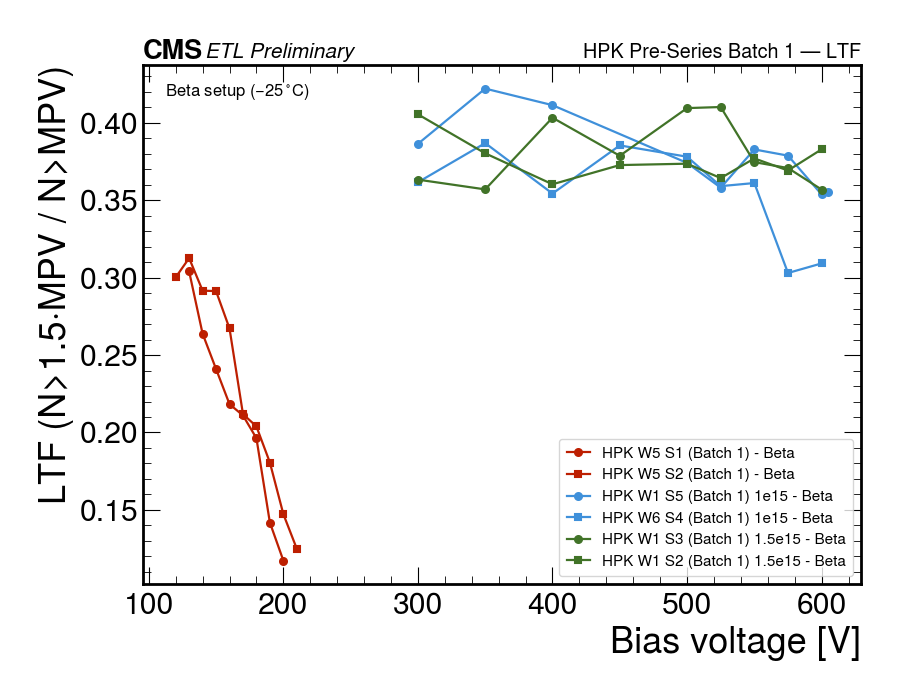

Salvato: LTF_images/hpk_b1_lft_vs_charge.png


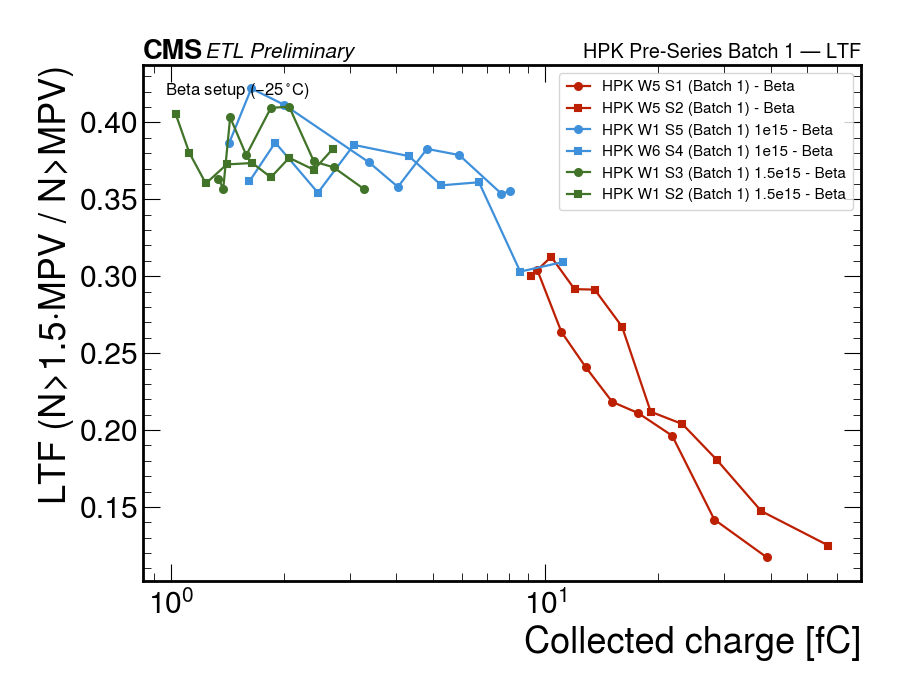

In [181]:
# ── Cosa plottare ────────────────────────────────────────────
selection = [0,1,2,3,4,5]          # HPK Batch 1: non-irr, 1e15, 1.5e15
TITLE     = "HPK Pre-Series Batch 1 — LTF"
SUBTITLE  = r"Beta setup ($-25^\circ$C)"

# ── Limiti degli assi (None = automatico) ────────────────────
YLIM    = None    # es. (0, 0.5)
XLIM_V  = None    # es. (100, 600)   bias [V]
XLIM_Q  = None    # es. (0, 60)      carica [fC]
XLOG_Q  = True   # True -> asse x della carica in scala log

# ── Nome file (salvataggio: vedi SAVE_IMAGES) ────────────────
PROD_NAME = "hpk_b1"    # -> {PROD_NAME}_lft_vs_bias.png, ..._vs_charge.png

plot_two(selection, TITLE, subtitle=SUBTITLE, ylim=YLIM,
         xlim_v=XLIM_V, xlim_q=XLIM_Q, xlog_q=XLOG_Q, name=PROD_NAME)


Salvato: LTF_images/hpk_b2_lft_vs_bias.png


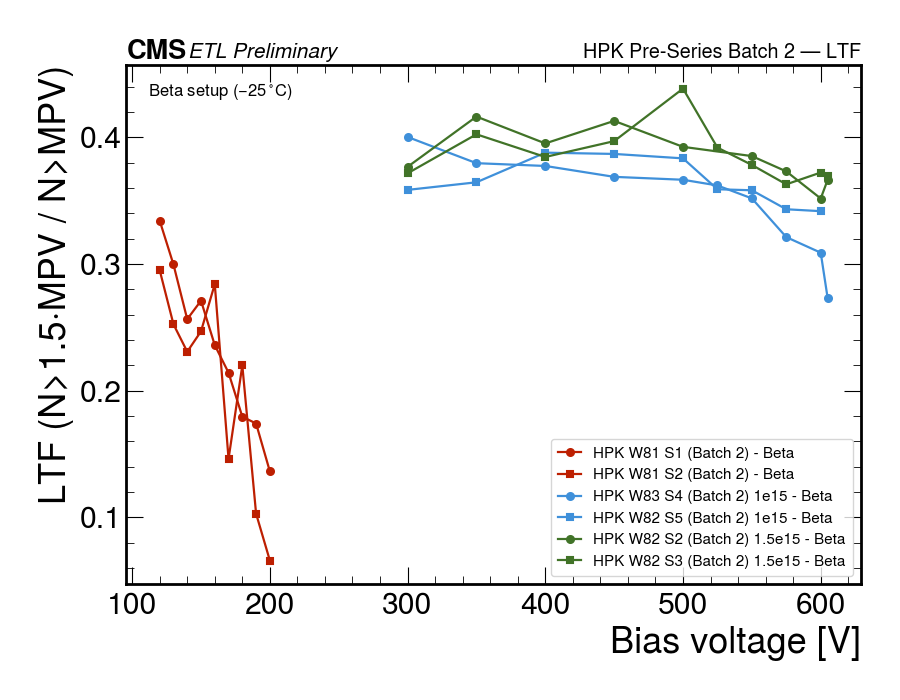

Salvato: LTF_images/hpk_b2_lft_vs_charge.png


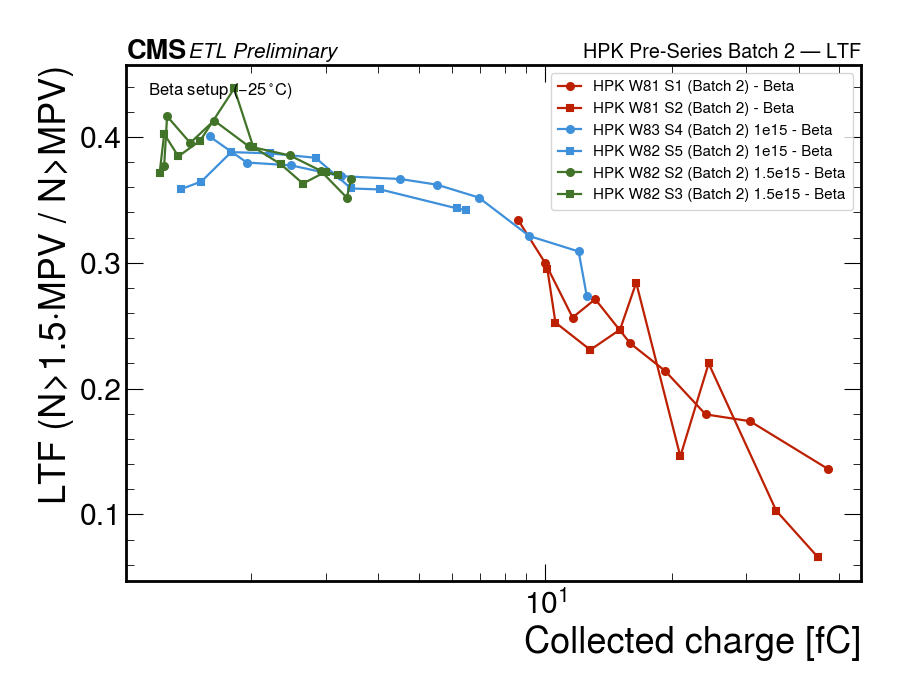

In [182]:
# ── Cosa plottare ────────────────────────────────────────────
selection = [6,7,8,9,10,11]          # HPK Batch 2
TITLE     = "HPK Pre-Series Batch 2 — LTF"
SUBTITLE  = r"Beta setup ($-25^\circ$C)"

# ── Limiti degli assi (None = automatico) ────────────────────
YLIM    = None    # es. (0, 0.5)
XLIM_V  = None    # es. (100, 600)   bias [V]
XLIM_Q  = None    # es. (0, 60)      carica [fC]
XLOG_Q  = True   # True -> asse x della carica in scala log

# ── Nome file (salvataggio: vedi SAVE_IMAGES) ────────────────
PROD_NAME = "hpk_b2"    # -> {PROD_NAME}_lft_vs_bias.png, ..._vs_charge.png

plot_two(selection, TITLE, subtitle=SUBTITLE, ylim=YLIM,
         xlim_v=XLIM_V, xlim_q=XLIM_Q, xlog_q=XLOG_Q, name=PROD_NAME)


Salvato: LTF_images/hpk6_lft_vs_bias.png


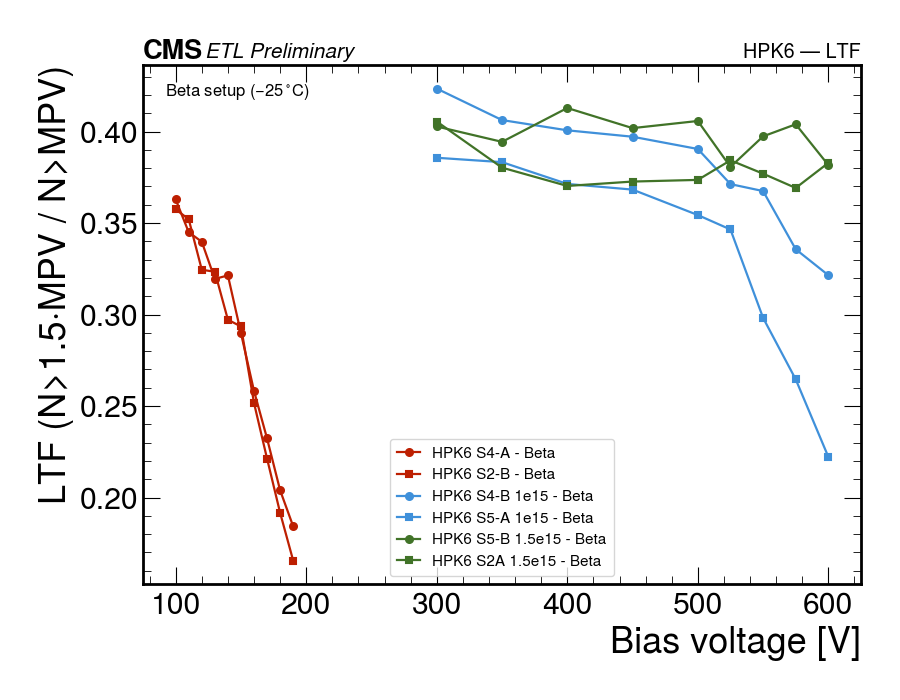

Salvato: LTF_images/hpk6_lft_vs_charge.png


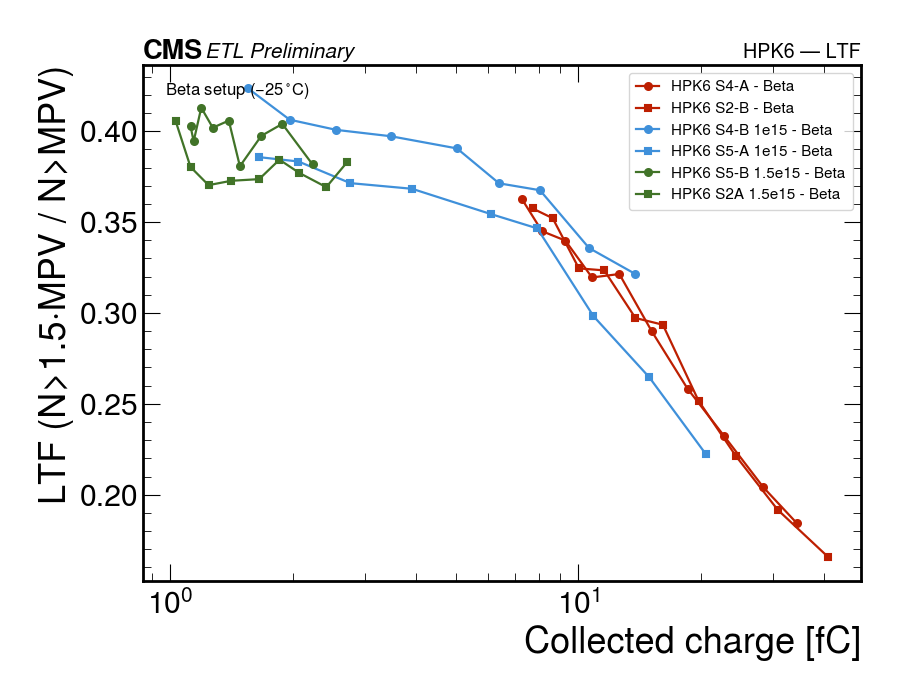

In [183]:
# ── Cosa plottare ────────────────────────────────────────────
selection = [12,13,14,15,16,17]          # HPK6
TITLE     = "HPK6 — LTF"
SUBTITLE  = r"Beta setup ($-25^\circ$C)"

# ── Limiti degli assi (None = automatico) ────────────────────
YLIM    = None    # es. (0, 0.5)
XLIM_V  = None    # es. (100, 600)   bias [V]
XLIM_Q  = None    # es. (0, 60)      carica [fC]
XLOG_Q  = True   # True -> asse x della carica in scala log

# ── Nome file (salvataggio: vedi SAVE_IMAGES) ────────────────
PROD_NAME = "hpk6"    # -> {PROD_NAME}_lft_vs_bias.png, ..._vs_charge.png

plot_two(selection, TITLE, subtitle=SUBTITLE, ylim=YLIM,
         xlim_v=XLIM_V, xlim_q=XLIM_Q, xlog_q=XLOG_Q, name=PROD_NAME)


Salvato: LTF_images/fbk_lft_vs_bias.png


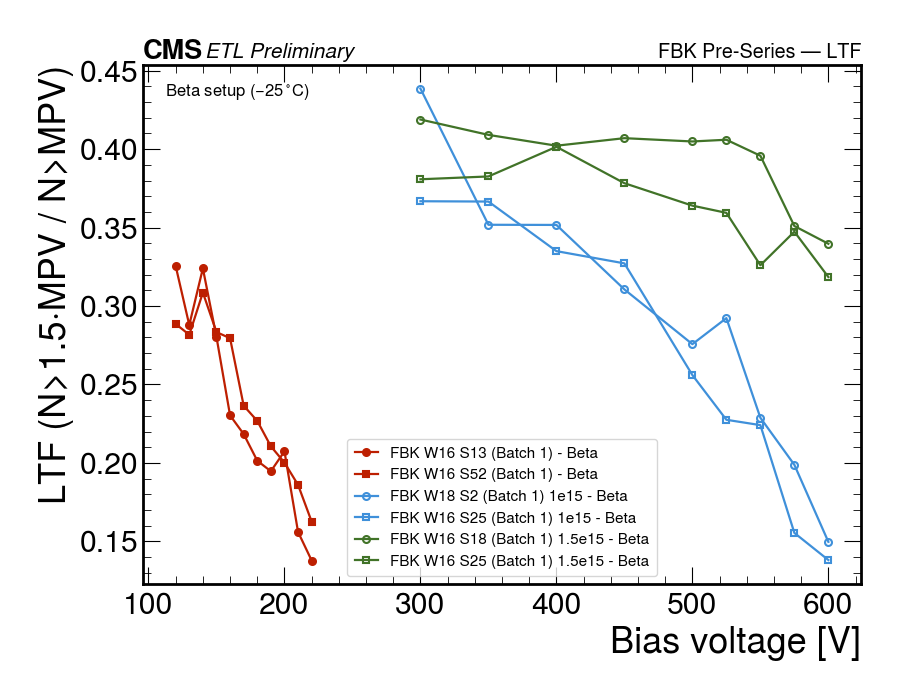

Salvato: LTF_images/fbk_lft_vs_charge.png


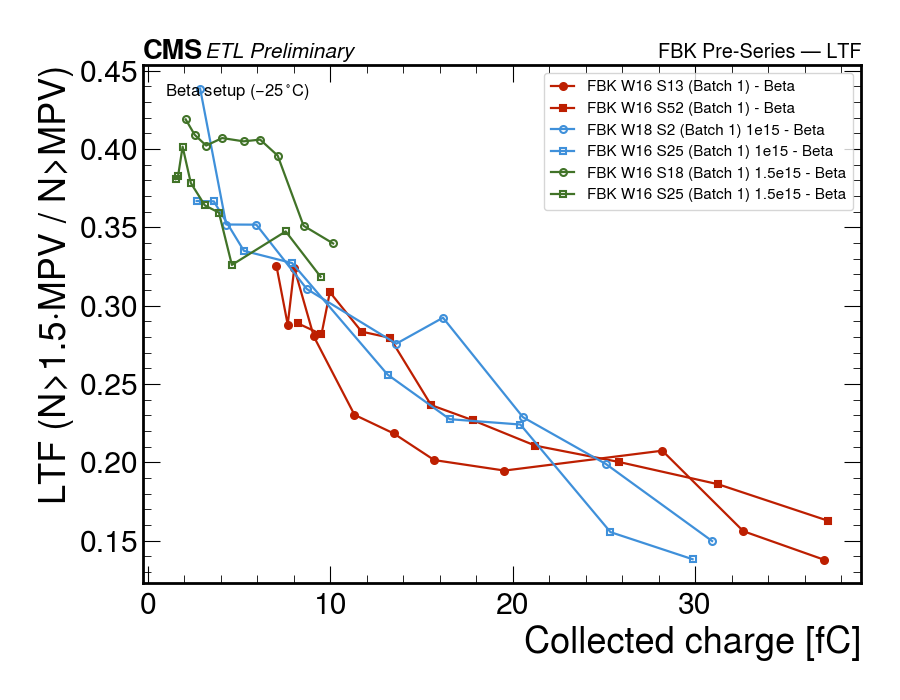

In [184]:
# ── Cosa plottare ────────────────────────────────────────────
selection = [18,19,20,21,22,23]          # FBK Batch 1
TITLE     = "FBK Pre-Series — LTF"
SUBTITLE  = r"Beta setup ($-25^\circ$C)"

# ── Limiti degli assi (None = automatico) ────────────────────
YLIM    = None    # es. (0, 0.5)
XLIM_V  = None    # es. (100, 600)   bias [V]
XLIM_Q  = None    # es. (0, 60)      carica [fC]
XLOG_Q  = False   # True -> asse x della carica in scala log

# ── Nome file (salvataggio: vedi SAVE_IMAGES) ────────────────
PROD_NAME = "fbk"    # -> {PROD_NAME}_lft_vs_bias.png, ..._vs_charge.png

plot_two(selection, TITLE, subtitle=SUBTITLE, ylim=YLIM,
         xlim_v=XLIM_V, xlim_q=XLIM_Q, xlog_q=XLOG_Q, name=PROD_NAME)


Salvato: LTF_images/all_lft_vs_bias.png


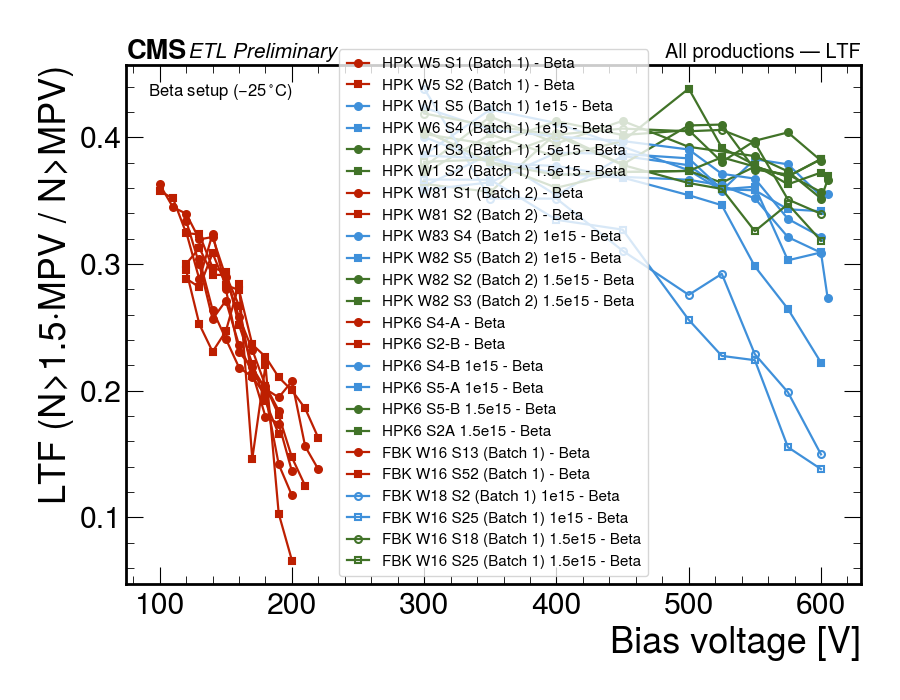

Salvato: LTF_images/all_lft_vs_charge.png


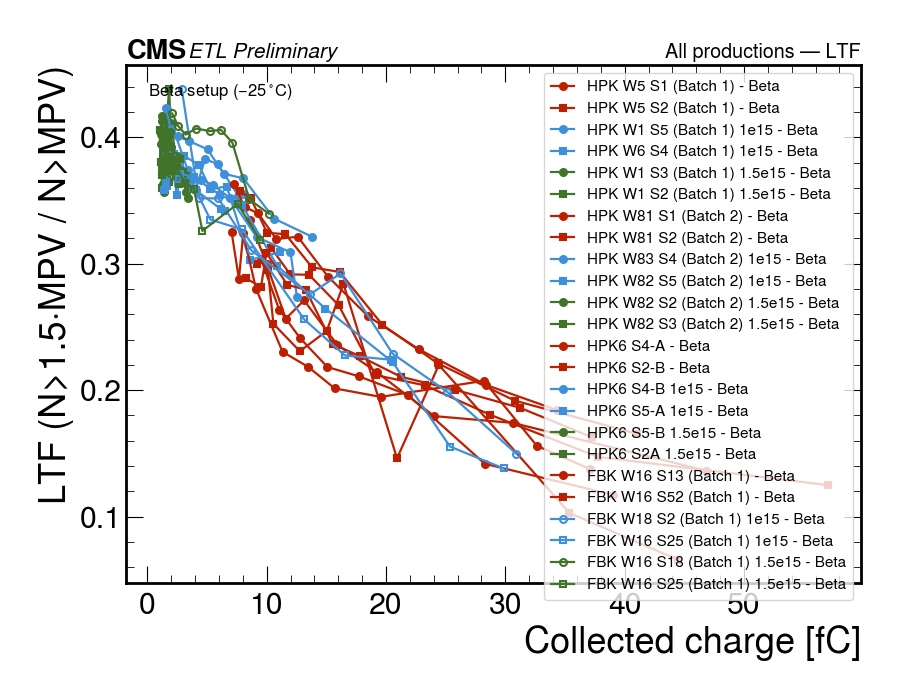

In [185]:
# ── Cosa plottare ────────────────────────────────────────────
selection = 'all'          # indici, intero singolo, o 'all'
TITLE     = "All productions — LTF"
SUBTITLE  = r"Beta setup ($-25^\circ$C)"

# ── Limiti degli assi (None = automatico) ────────────────────
YLIM    = None    # es. (0, 0.5)
XLIM_V  = None    # es. (100, 600)   bias [V]
XLIM_Q  = None    # es. (0, 60)      carica [fC]
XLOG_Q  = False   # True -> asse x della carica in scala log

# ── Nome file (salvataggio: vedi SAVE_IMAGES) ────────────────
PROD_NAME = "all"    # -> {PROD_NAME}_lft_vs_bias.png, ..._vs_charge.png

plot_two(selection, TITLE, subtitle=SUBTITLE, ylim=YLIM,
         xlim_v=XLIM_V, xlim_q=XLIM_Q, xlog_q=XLOG_Q, name=PROD_NAME)
